Name: Jiahe Yi
<br>
Github Username: beaverjuly
<br>
USC ID: 5689143499

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

In [1]:
# All imports for the entire notebook live in this single cell.
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
try:
    from statsmodels.tools.sm_exceptions import PerfectSeparationError
except ImportError:                       # kept working if a future version removes it
    PerfectSeparationError = np.linalg.LinAlgError

import sklearn
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score

warnings.filterwarnings("ignore")

RANDOM_STATE = 552
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

# scikit learn 1.8 deprecates the penalty argument in favour of l1_ratio, while
# older versions ignore l1_ratio unless penalty is elasticnet. This picks the
# argument that gives an L1 penalty on whichever version is installed.
SKLEARN_18 = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)
L1_ARGS = {"l1_ratio": 1.0} if SKLEARN_18 else {"penalty": "l1"}

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit learn", sklearn.__version__,
      "| statsmodels", sm.__version__)

numpy 2.4.4 | pandas 3.0.2 | scikit learn 1.8.0 | statsmodels 0.15.0


In [2]:
# Load all 88 instances with a relative path. The loader handles the minor
# irregularities found in Homework 3 (a space delimited file, trailing commas,
# and one file with 479 rows) without editing the raw files.
DATA_DIR_CANDIDATES = ["data/AReM", "../data/AReM"]
DATA_DIR = next((d for d in DATA_DIR_CANDIDATES if os.path.isdir(d)), None)
if DATA_DIR is None:
    raise FileNotFoundError("AReM folder not found in " + ", ".join(DATA_DIR_CANDIDATES))

ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def dataset_number(name):
    return int(re.findall(r"\d+", name)[0])


def load_instance(path):
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line_no, line in enumerate(fh, start=1):
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            tokens = [t for t in re.split(r"[,\s]+", line) if t != ""]
            if len(tokens) != 7:
                raise ValueError(f"{path}, line {line_no}: expected 7 fields, got {len(tokens)}")
            rows.append([float(t) for t in tokens])
    return pd.DataFrame(rows, columns=["time"] + SERIES)


instances = []
for act in ACTIVITIES:
    for f in sorted(os.listdir(DATA_DIR + "/" + act), key=dataset_number):
        if f.endswith(".csv"):
            instances.append({"activity": act, "dataset": dataset_number(f),
                              "data": load_instance(DATA_DIR + "/" + act + "/" + f)})
print("Loaded", len(instances), "instances from", DATA_DIR)

Loaded 88 instances from data/AReM


### (b) Splitting Data

In [3]:
# Test set is datasets 1 and 2 of bending1 and bending2, and datasets 1, 2 and 3
# of every other activity. Everything else is training data.
for r in instances:
    test_ids = (1, 2) if r["activity"] in ("bending1", "bending2") else (1, 2, 3)
    r["split"] = "test" if r["dataset"] in test_ids else "train"

meta = pd.DataFrame({k: [r[k] for r in instances] for k in ["activity", "dataset", "split"]},
                    index=pd.RangeIndex(1, len(instances) + 1, name="Instance"))
train = (meta["split"] == "train").to_numpy()
test = ~train
y_bin = meta["activity"].isin(["bending1", "bending2"]).astype(int).to_numpy()   # 1 = bending
y_multi = meta["activity"].to_numpy()

print(pd.crosstab(meta["activity"], meta["split"]).reindex(ACTIVITIES).to_string())
print("\nTraining instances", train.sum(), "of which bending", y_bin[train].sum())
print("Test instances", test.sum(), "of which bending", y_bin[test].sum())

split     test  train
activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12

Training instances 69 of which bending 9
Test instances 19 of which bending 4


### (c) Feature Extraction

In [4]:
# Seven time domain features for every part of every series. Each series is
# split into l parts of almost equal length with np.array_split, so l = 1 gives
# the 42 features of Homework 3 and a general l gives 42 * l features.
STATS = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]


def part_features(x):
    q1, q3 = np.percentile(x, [25, 75])
    return [x.min(), x.max(), x.mean(), np.median(x), x.std(ddof=1), q1, q3]


def extract_features(l):
    rows = []
    for r in instances:
        row = {}
        for i, s in enumerate(SERIES, start=1):
            for j, part in enumerate(np.array_split(r["data"][s].to_numpy(), l), start=1):
                for name, value in zip(STATS, part_features(part)):
                    row[f"{name}{i}_{j}"] = value      # e.g. mean2_3 is the mean of part 3 of series 2
        rows.append(row)
    return pd.DataFrame(rows, index=meta.index)


L_VALUES = list(range(1, 21))
FEATURES = {l: extract_features(l) for l in L_VALUES}
print("Features for l = 1 to 20 extracted. Shapes for l = 1, 2 and 20:",
      FEATURES[1].shape, FEATURES[2].shape, FEATURES[20].shape)
FEATURES[1].head()

Features for l = 1 to 20 extracted. Shapes for l = 1, 2 and 20: (88, 42) (88, 84) (88, 840)


,min1_1,max1_1,mean1_1,median1_1,std1_1,1st_quart1_1,3rd_quart1_1,min2_1,max2_1,mean2_1,median2_1,std2_1,1st_quart2_1,3rd_quart2_1,min3_1,max3_1,mean3_1,median3_1,std3_1,1st_quart3_1,3rd_quart3_1,min4_1,max4_1,mean4_1,median4_1,std4_1,1st_quart4_1,3rd_quart4_1,min5_1,max5_1,mean5_1,median5_1,std5_1,1st_quart5_1,3rd_quart5_1,min6_1,max6_1,mean6_1,median6_1,std6_1,1st_quart6_1,3rd_quart6_1
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

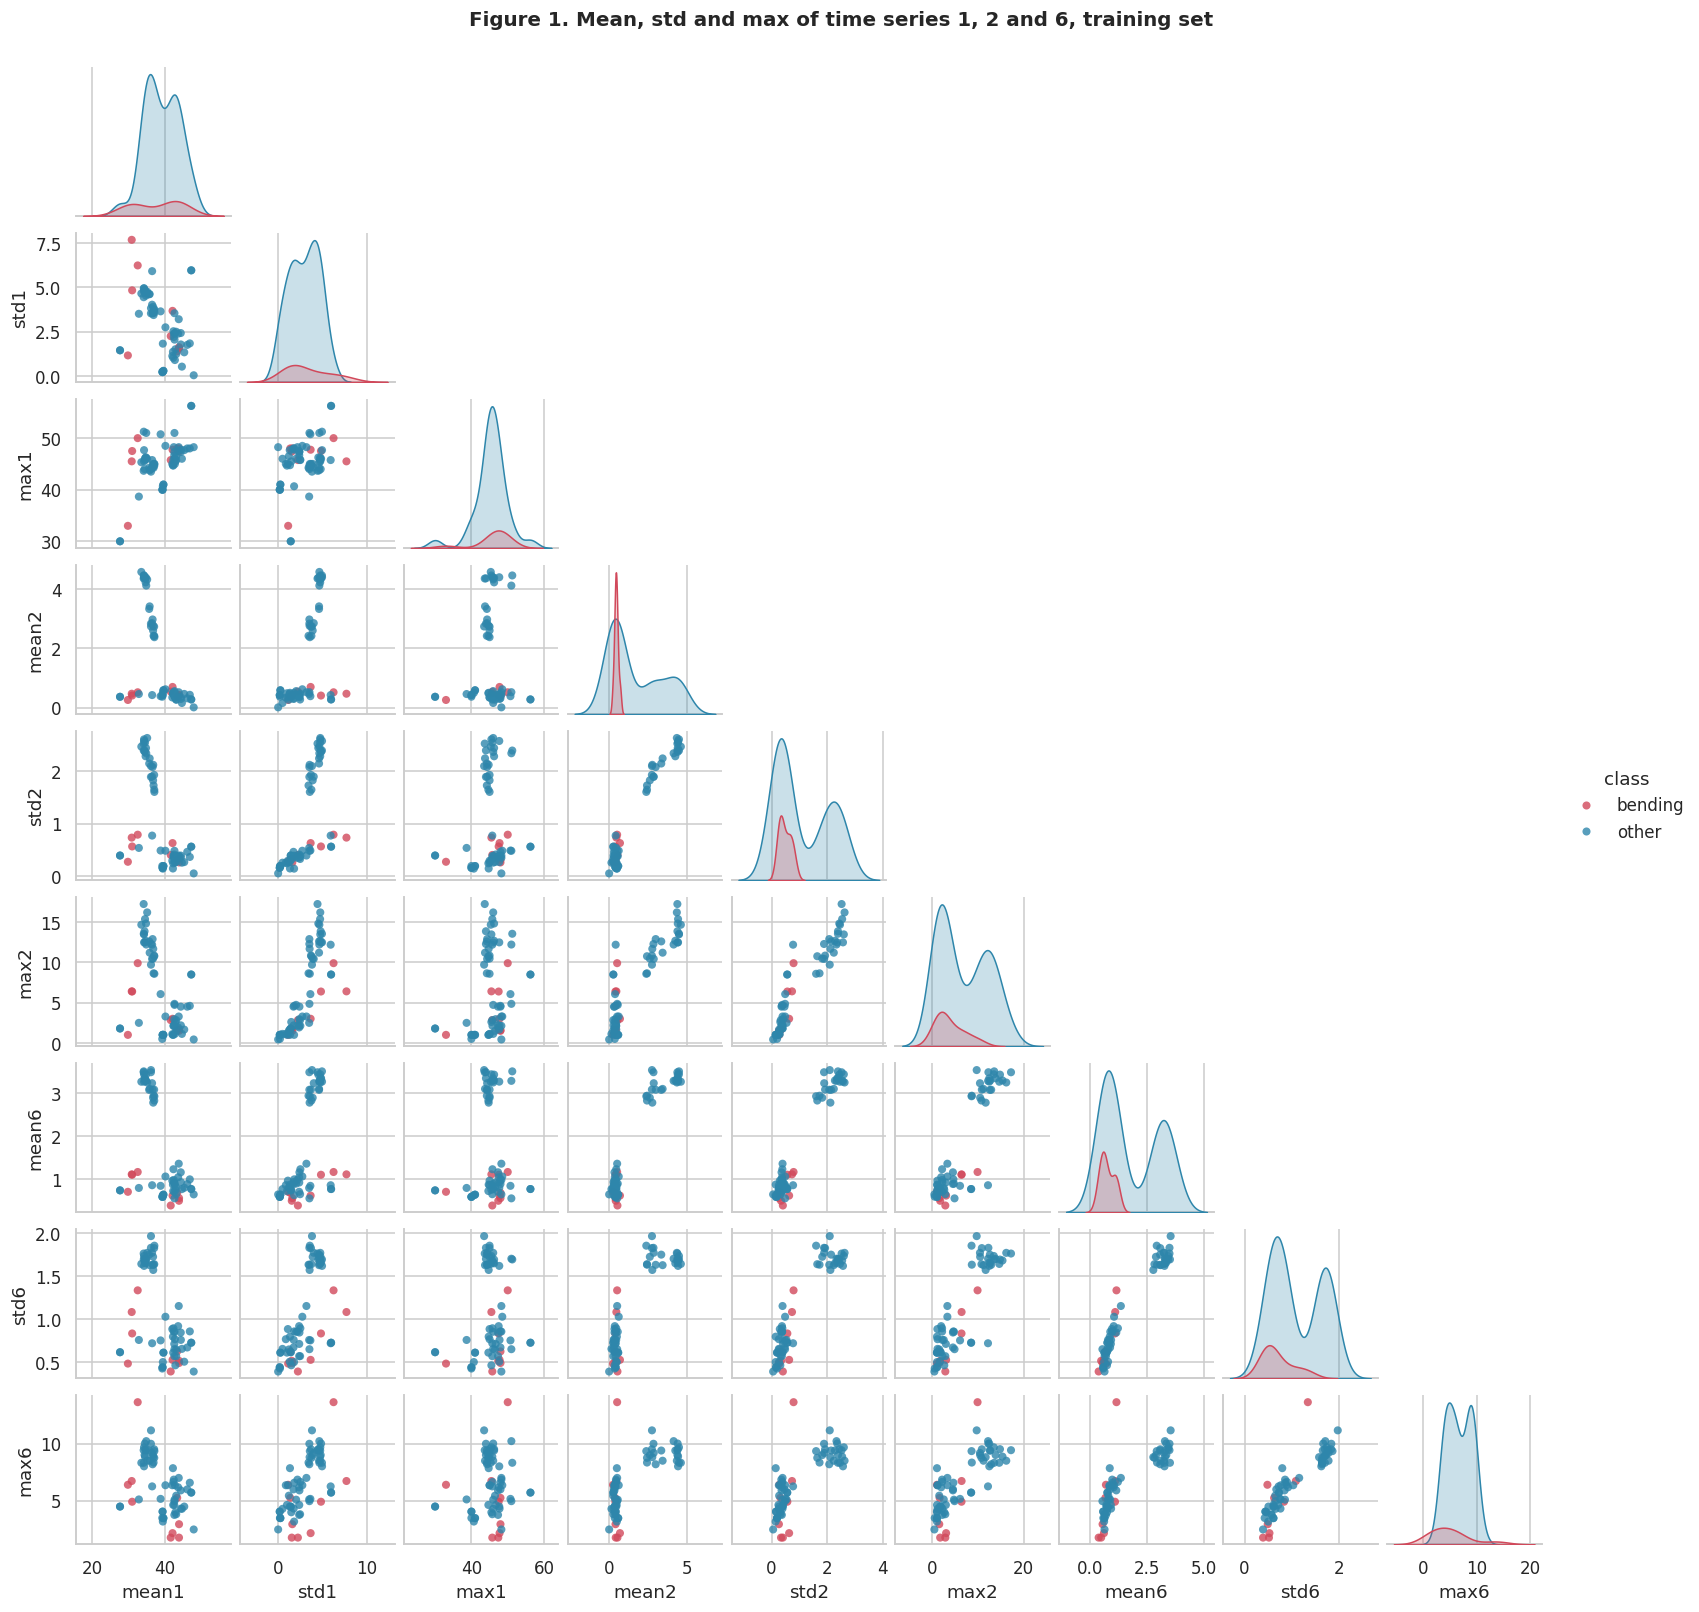

Pairs that separate bending perfectly: 0 of 36
Best pair std1 and max6, training accuracy 0.899
Always predicting other gives 0.870


In [5]:
# The three features chosen in Homework 3, 1(c)iv, for time series 1, 2 and 6.
SELECTED_STATS = ["mean", "std", "max"]
PALETTE = {"bending": "#D1495B", "other": "#2E86AB"}


def scatter_frame(l, part):
    cols = [f"{s}{i}_{part}" for i in (1, 2, 6) for s in SELECTED_STATS]
    df = FEATURES[l].loc[train, cols].copy()
    df.columns = [c.rsplit("_", 1)[0] for c in cols]       # mean1_1 becomes mean1
    df["class"] = np.where(y_bin[train] == 1, "bending", "other")
    return df


g = sns.pairplot(scatter_frame(1, 1), hue="class", palette=PALETTE, corner=True, diag_kind="kde",
                 plot_kws=dict(s=28, alpha=0.8, edgecolor="none"), height=1.6)
g.figure.suptitle("Figure 1. Mean, std and max of time series 1, 2 and 6, training set",
                  y=1.02, fontsize=13, fontweight="bold")
plt.show()


def linear_training_accuracy(X, y):
    """Best training accuracy of two linear classifiers. 1.0 means linearly separable."""
    X = StandardScaler().fit_transform(X)
    return max(LinearSVC(C=1e6, max_iter=200000).fit(X, y).score(X, y),
               LogisticRegression(C=1e10, max_iter=100000, tol=1e-12).fit(X, y).score(X, y))


def best_pair(df):
    feats = [c for c in df.columns if c != "class"]
    y = (df["class"] == "bending").astype(int).to_numpy()
    scores = {(a, b): linear_training_accuracy(df[[a, b]].to_numpy(), y)
              for i, a in enumerate(feats) for b in feats[i + 1:]}
    pair = max(scores, key=scores.get)
    return pair, scores[pair], sum(v == 1.0 for v in scores.values()), len(scores)


pair, acc, n_sep, n_pairs = best_pair(scatter_frame(1, 1))
print(f"Pairs that separate bending perfectly: {n_sep} of {n_pairs}")
print(f"Best pair {pair[0]} and {pair[1]}, training accuracy {acc:.3f}")
print(f"Always predicting other gives {1 - y_bin[train].mean():.3f}")

2(a)i. Figure 1 shows the pairwise scatter plots of the mean, standard deviation and maximum of time series 1, 2 and 6 for the 69 training instances, with bending in red and all other activities in blue. The features of the variance series 2 and 6 split the other activities into a group with large values, which are the dynamic activities walking and cycling, and a group with small values. The bending instances lie in the group with small values together with the static activities, so these features separate bending from walking and cycling but not from the static postures.

No single feature separates bending from the other activities, and no pair does either. I checked all 36 pairs with a linear classifier, and the best pair, std1 and max6, classifies only 89.9% of the training instances correctly, barely more than the 87.0% obtained by always predicting other.

#### ii. Splitted Plots

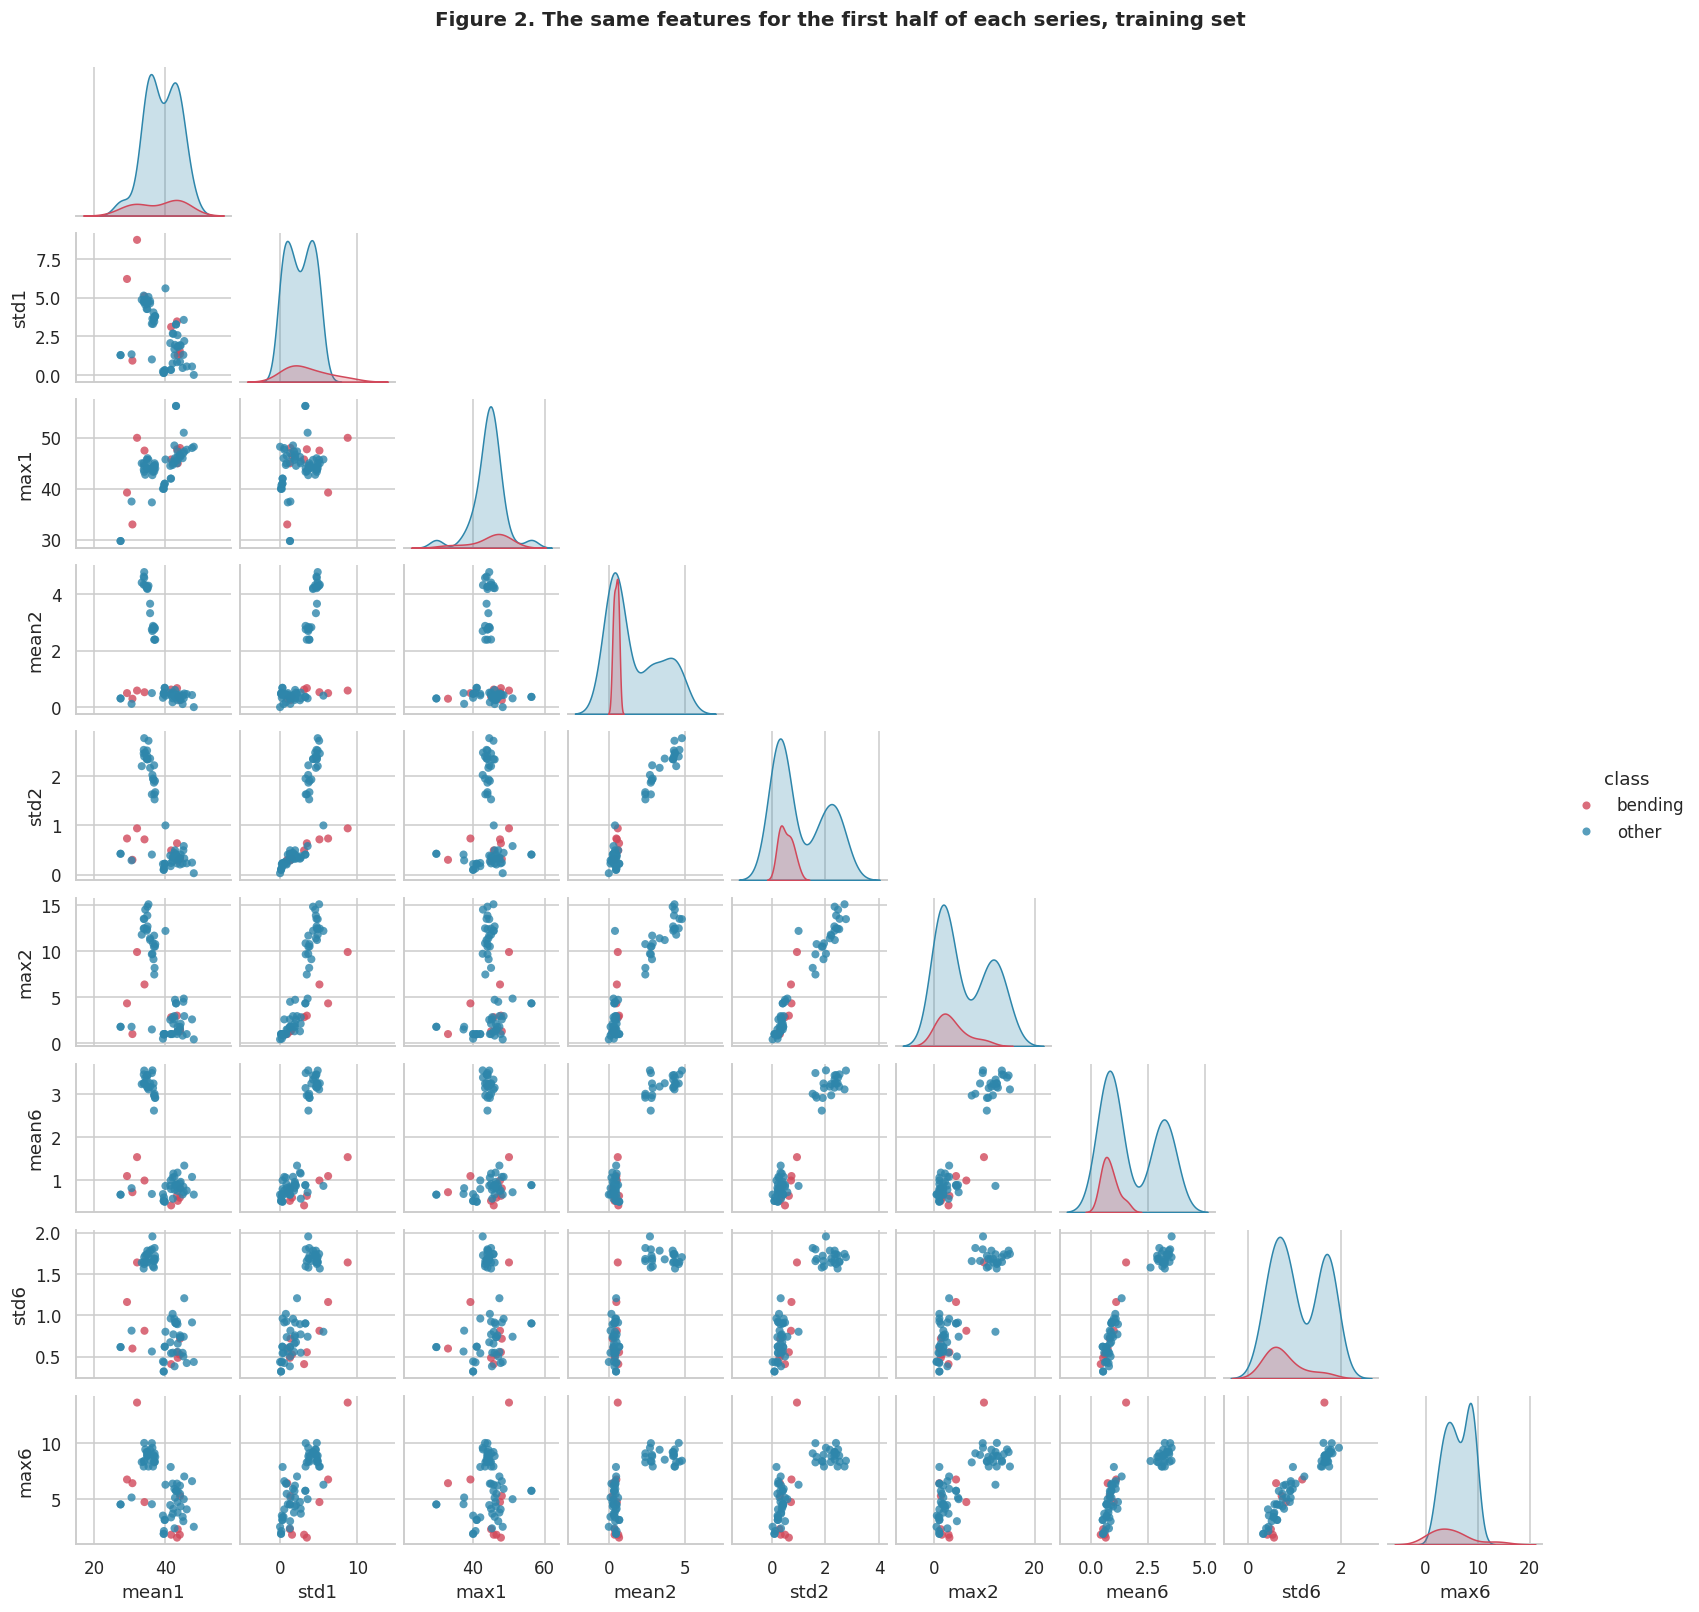

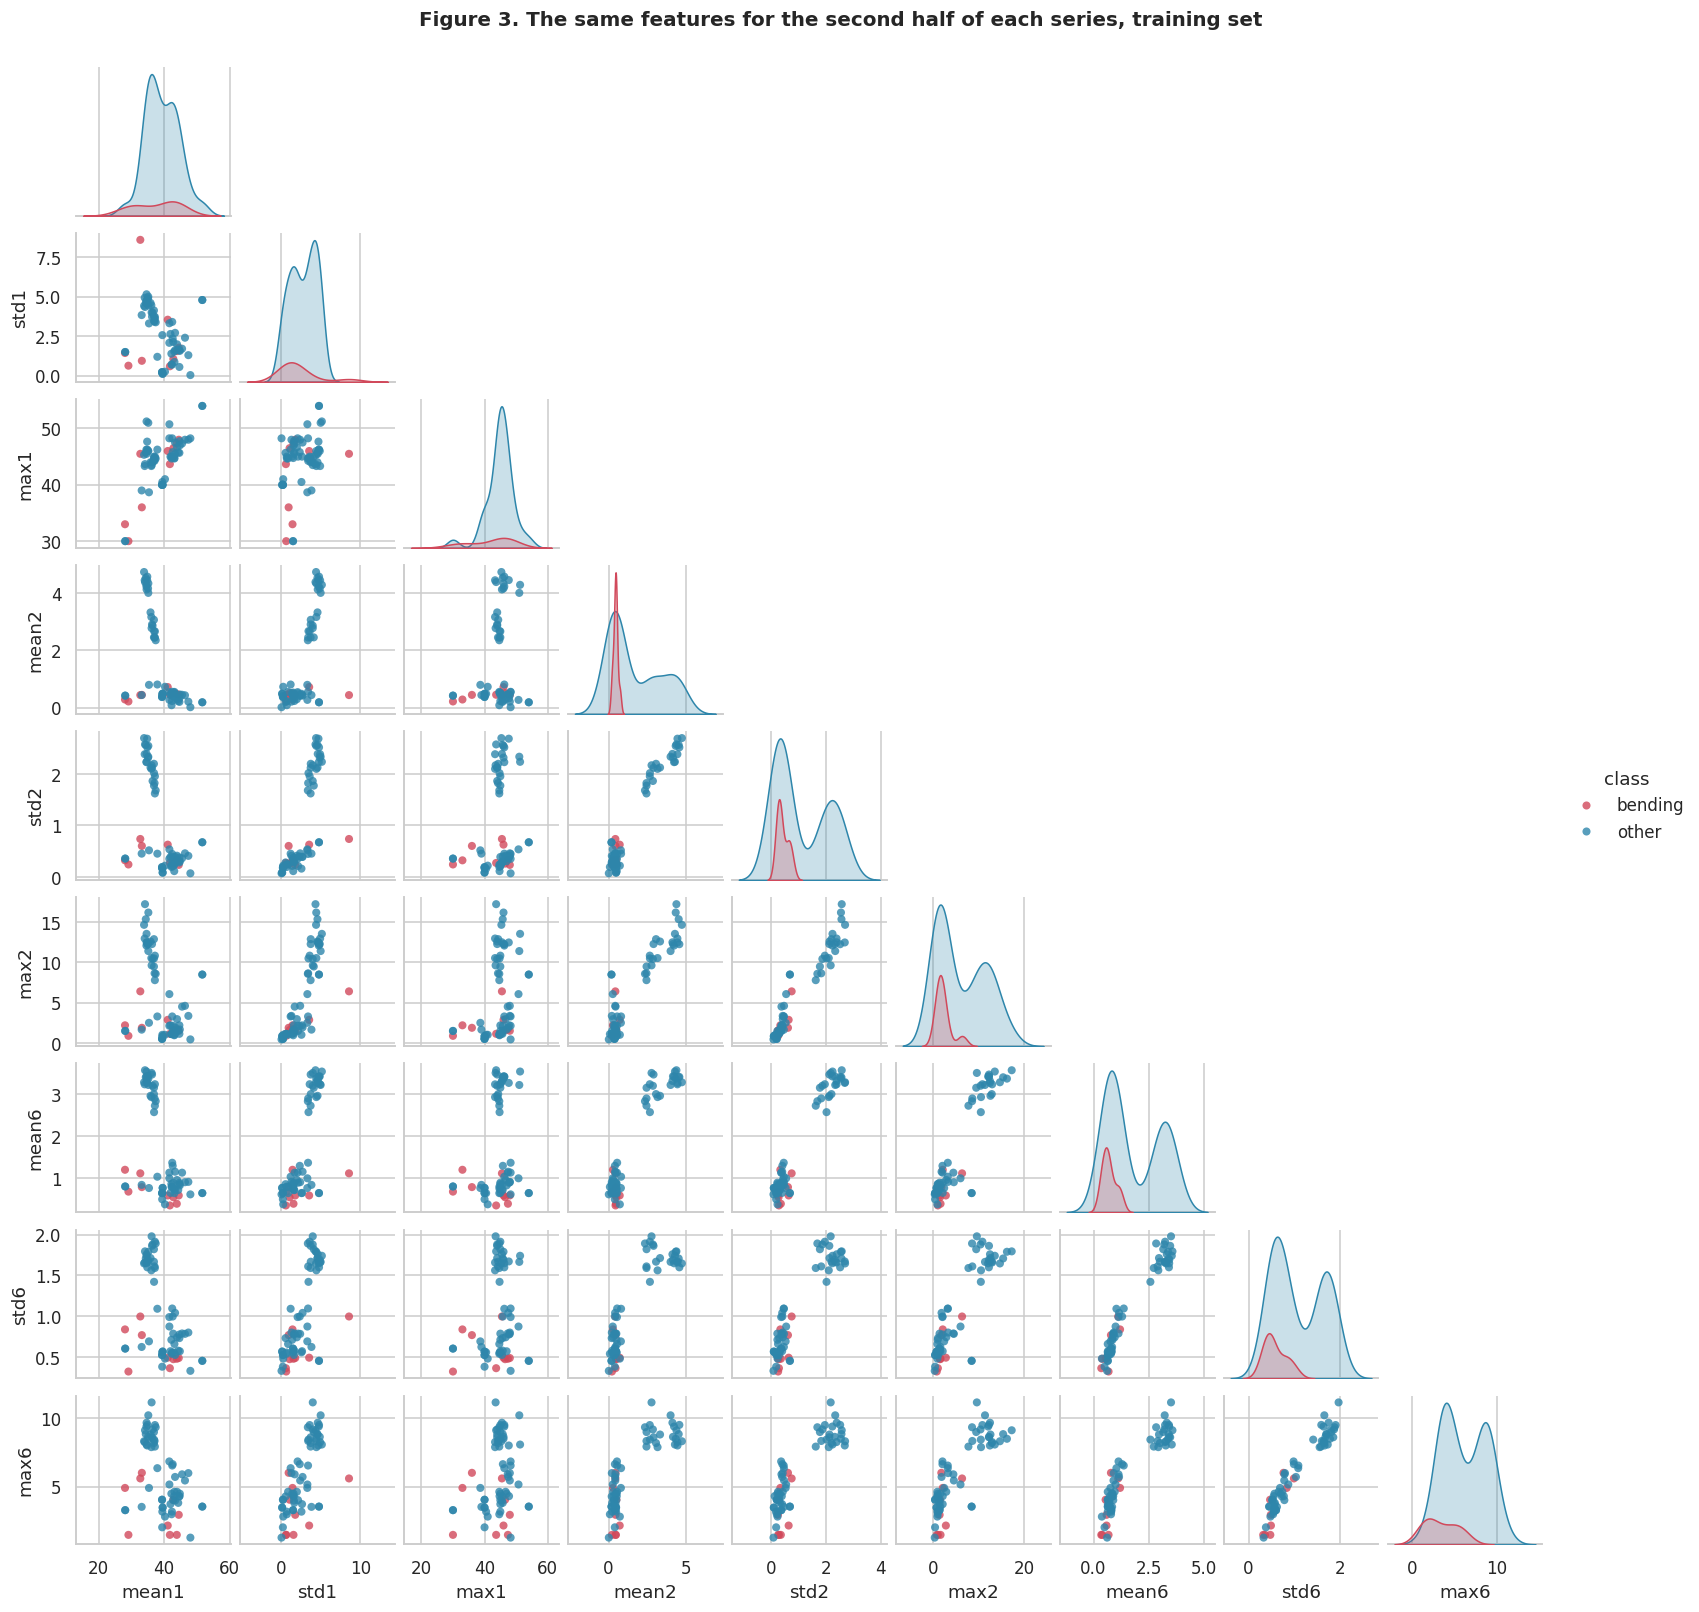

In [6]:
for part, fig_no in [(1, 2), (2, 3)]:
    g = sns.pairplot(scatter_frame(2, part), hue="class", palette=PALETTE, corner=True, diag_kind="kde",
                     plot_kws=dict(s=28, alpha=0.8, edgecolor="none"), height=1.6)
    half = "first" if part == 1 else "second"
    g.figure.suptitle(f"Figure {fig_no}. The same features for the {half} half of each series, training set",
                      y=1.02, fontsize=13, fontweight="bold")
    plt.show()

In [7]:
# Compare the full series with the two halves numerically.
cols = [f"{s}{i}" for i in (1, 2, 6) for s in SELECTED_STATS]


def standardized_difference(col):
    a, b = col[train & (y_bin == 1)], col[train & (y_bin == 0)]
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return abs(a.mean() - b.mean()) / pooled


halves = pd.DataFrame({
    "full series": [standardized_difference(FEATURES[1][c + "_1"]) for c in cols],
    "first half": [standardized_difference(FEATURES[2][c + "_1"]) for c in cols],
    "second half": [standardized_difference(FEATURES[2][c + "_2"]) for c in cols],
    "corr between halves": [np.corrcoef(FEATURES[2][c + "_1"][train], FEATURES[2][c + "_2"][train])[0, 1]
                            for c in cols],
}, index=cols)
print("Absolute standardized difference between bending and other, and the correlation")
print("of each feature between the two halves (training set)")
print(halves.round(2).to_string())

print("\nLinear separability of bending versus other, training set")
for label, l, part in [("full series", 1, 1), ("first half", 2, 1), ("second half", 2, 2)]:
    df = scatter_frame(l, part)
    pair, acc, n_sep, n_pairs = best_pair(df)
    all_nine = linear_training_accuracy(df.drop(columns="class").to_numpy(), y_bin[train])
    print(f"  {label:11s}  separating pairs {n_sep} of {n_pairs}, best pair {pair[0]} and {pair[1]} "
          f"at {acc:.3f}, all nine features together {all_nine:.3f}")

Absolute standardized difference between bending and other, and the correlation
of each feature between the two halves (training set)
       full series  first half  second half  corr between halves
mean1         0.29        0.20         0.37                 0.88
std1          0.25        0.51         0.30                 0.70
max1          0.12        0.10         0.65                 0.66
mean2         0.78        0.76         0.79                 0.99
std2          0.68        0.60         0.74                 0.98
max2          0.57        0.52         0.78                 0.89
mean6         0.91        0.85         0.96                 0.98
std6          0.80        0.63         0.98                 0.93
max6          0.65        0.50         1.13                 0.80

Linear separability of bending versus other, training set
  full series  separating pairs 0 of 36, best pair std1 and max6 at 0.899, all nine features together 0.957


  first half   separating pairs 0 of 36, best pair std1 and std6 at 0.928, all nine features together 1.000


  second half  separating pairs 0 of 36, best pair std1 and max6 at 0.899, all nine features together 0.942


2(a)ii. Figures 2 and 3 show the same scatter plots for the first and the second half of each time series. I do not see a considerable difference from 2(a)i. Both halves show the same two groups of other activities, and bending again lies among the static activities.

The tables above make this concrete. For the variance series 2 and 6 the features of the two halves are almost the same, with correlations between halves of 0.80 to 0.99 across instances, so splitting adds little new information there. The features of series 1 change more between halves, with correlations of 0.66 for max1, 0.70 for std1 and 0.88 for mean1, and a few features separate the groups somewhat better in one half, most clearly max6 in the second half, with a standardized difference of 1.13 compared with 0.65 for the full series. Still, no pair of features separates the classes in either half, and the best pairs reach 92.8% and 89.9% training accuracy, compared with 89.9% for the full series.

The one clear difference appears only when all nine features are used together. With the nine features of the first half a linear classifier separates the training classes perfectly, whereas it reaches 95.7% with the nine full series features and 94.2% with those of the second half. Splitting therefore adds some information in combination, but nothing that is visible in the scatter plots.

#### iii. Time Series Segments

In [8]:
# Recursive feature elimination with an unpenalized logistic regression,
# cross validated over (l, p). C = 1e10 removes the default L2 penalty
# (footnote 3). RFE removes 10% of the remaining features per round until
# P_MAX remain, then one at a time, which gives an exact ranking of those P_MAX.
P_MAX = 15
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)


def unpenalized_lr():
    return LogisticRegression(C=1e10, max_iter=100)


def rfe_order(X, y, p_max=P_MAX):
    """Indices of the p_max most important features, most important first."""
    keep = np.arange(X.shape[1])
    if len(keep) > p_max:
        keep = keep[RFE(unpenalized_lr(), n_features_to_select=p_max, step=0.1).fit(X, y).support_]
    ranking = RFE(unpenalized_lr(), n_features_to_select=1, step=1).fit(X[:, keep], y).ranking_
    return keep[np.argsort(ranking)]


def best_cell(grid, key):
    """Best cell of a grid, breaking ties with key (smaller is simpler)."""
    top = grid.max()
    cells = [(i, j) for i in range(grid.shape[0]) for j in range(grid.shape[1])
             if np.isclose(grid[i, j], top)]
    return min(cells, key=key), top, len(cells)


# The right way. Scaling, RFE and the final fit all use only the training part
# of each fold, and the held out part is used only for evaluation.
cv_acc = np.zeros((len(L_VALUES), P_MAX))
for li, l in enumerate(L_VALUES):
    X, y = FEATURES[l].to_numpy()[train], y_bin[train]
    for tr, va in cv5.split(X, y):
        scaler_fold = StandardScaler().fit(X[tr])
        X_tr, X_va = scaler_fold.transform(X[tr]), scaler_fold.transform(X[va])
        order = rfe_order(X_tr, y[tr])
        for p in range(1, P_MAX + 1):
            model = unpenalized_lr().fit(X_tr[:, order[:p]], y[tr])
            cv_acc[li, p - 1] += accuracy_score(y[va], model.predict(X_va[:, order[:p]])) / 5

(li_star, pi_star), cv_best, n_tied = best_cell(cv_acc, key=lambda c: (c[1], c[0]))
L_STAR, P_STAR = L_VALUES[li_star], pi_star + 1
print(f"Best cross validated accuracy {cv_best:.4f} at l = {L_STAR}, p = {P_STAR} ({n_tied} pair(s) at the maximum)")
print("\nBest accuracy over p for each l")
print(pd.Series(cv_acc.max(axis=1), index=pd.Index(L_VALUES, name="l")).round(3).to_string())
print(f"\nAccuracy at l = {L_STAR} for p = 1 to {P_MAX}")
print(np.round(cv_acc[li_star], 3))

Best cross validated accuracy 0.9857 at l = 1, p = 12 (1 pair(s) at the maximum)

Best accuracy over p for each l
l
1     0.986
2     0.971
3     0.942
4     0.927
5     0.942
6     0.956
7     0.943
8     0.927
9     0.927
10    0.957
11    0.926
12    0.957
13    0.957
14    0.956
15    0.942
16    0.929
17    0.956
18    0.942
19    0.970
20    0.956

Accuracy at l = 1 for p = 1 to 15
[0.943 0.941 0.97  0.955 0.941 0.971 0.957 0.957 0.957 0.971 0.971 0.986
 0.971 0.971 0.971]


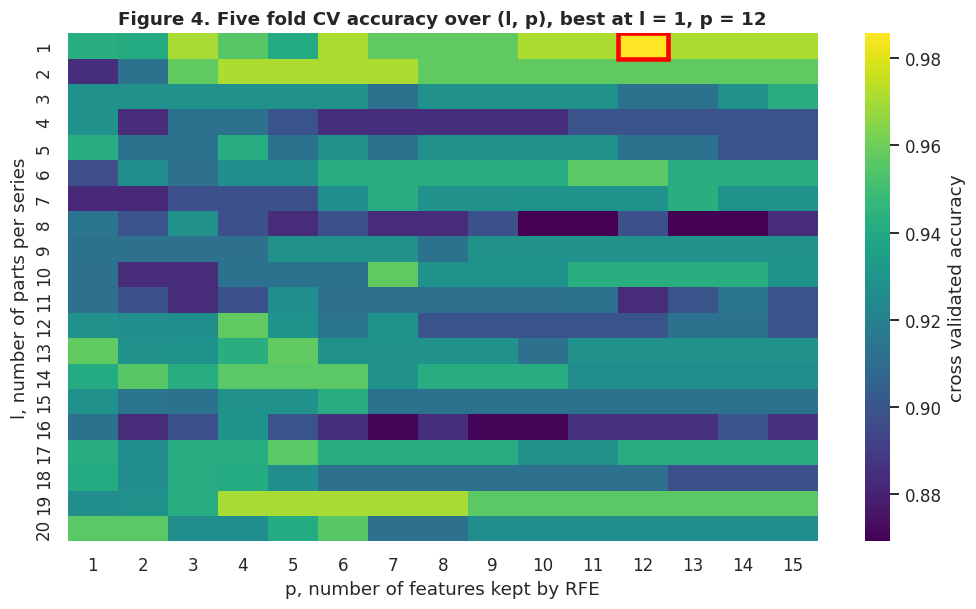

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pd.DataFrame(cv_acc, index=L_VALUES, columns=range(1, P_MAX + 1)), cmap="viridis",
            cbar_kws={"label": "cross validated accuracy"}, ax=ax)
ax.add_patch(plt.Rectangle((pi_star, li_star), 1, 1, fill=False, edgecolor="red", lw=3))
ax.set_xlabel("p, number of features kept by RFE")
ax.set_ylabel("l, number of parts per series")
ax.set_title(f"Figure 4. Five fold CV accuracy over (l, p), best at l = {L_STAR}, p = {P_STAR}")
plt.show()

In [10]:
# The wrong way, for comparison. RFE runs once on the whole training set and
# only the logistic regression is cross validated, so the held out instances
# have already influenced which features were selected.
X_l = FEATURES[L_STAR].to_numpy()[train]
order_all = rfe_order(StandardScaler().fit_transform(X_l), y_bin[train])
wrong = [cross_val_score(make_pipeline(StandardScaler(), unpenalized_lr()), X_l[:, order_all[:p]],
                         y_bin[train], cv=cv5).mean() for p in range(1, P_MAX + 1)]
print(pd.DataFrame({"right way": cv_acc[li_star], "wrong way": wrong},
                   index=pd.Index(range(1, P_MAX + 1), name="p")).round(3).T.to_string())

p             1      2      3      4      5      6      7      8      9      10     11     12     13     14     15
right way  0.943  0.941  0.970  0.955  0.941  0.971  0.957  0.957  0.957  0.971  0.971  0.986  0.971  0.971  0.971
wrong way  0.913  0.956  0.986  1.000  1.000  1.000  1.000  1.000  1.000  1.000  0.986  1.000  1.000  1.000  0.986


2(a)iii. For each l from 1 to 20 I split every time series into l parts of almost equal length, extracted the seven time domain features from every part, and obtained 42l features per instance. I used recursive feature elimination (RFE) with an unpenalized logistic regression to rank the features, and five fold stratified cross validation to choose the pair (l, p), with p from 1 to 15. With only 9 bending instances in the training set, larger models would be far beyond what the data can support. Among tied pairs I would keep the one with the smallest p and then the smallest l.

Within the searched range, the best cross validated accuracy is 0.986 at l = 1 and p = 12, the unique best of the 300 pairs I compared. Its margin over smaller models is small, because with l = 1 the model with p = 3 already reaches 0.970, which corresponds to one more misclassified validation instance.

The right way to cross validate here is to repeat every step that uses the labels inside each fold. Within a fold, the scaler, the feature selection by RFE and the logistic regression are all fitted on the training part only, and the held out part is used only to measure accuracy. The pair (l, p) is chosen by the averaged validation accuracy, and the final model is refitted on the whole training set. The feature extraction itself can be done once in advance, because each instance's features come from its own time series and never from its label.

The wrong way is to select the features once using the whole training set and then cross validate only the logistic regression on those preselected features. The held out instances have then already influenced which features were chosen, so the estimate is optimistic. The last table shows this for l = 1. Done the wrong way, the cross validated accuracy reaches 1.000 for most values of p, while the right way never exceeds 0.986.

Bending is only 9 of the 69 training instances, so a plain random split could leave a fold with no bending instance at all. I therefore used stratified cross validation, which splits each class separately so that every fold keeps roughly the class proportions of the whole training set. Here every fold has 1 or 2 bending instances.

#### iv. Confusion Matrix

Selected features: min5_1, max5_1, 3rd_quart1_1, 1st_quart6_1, max4_1, 1st_quart4_1, mean5_1, 3rd_quart3_1, min1_1, max2_1, max1_1, std6_1
Training accuracy 1.0 | training AUC 1.0


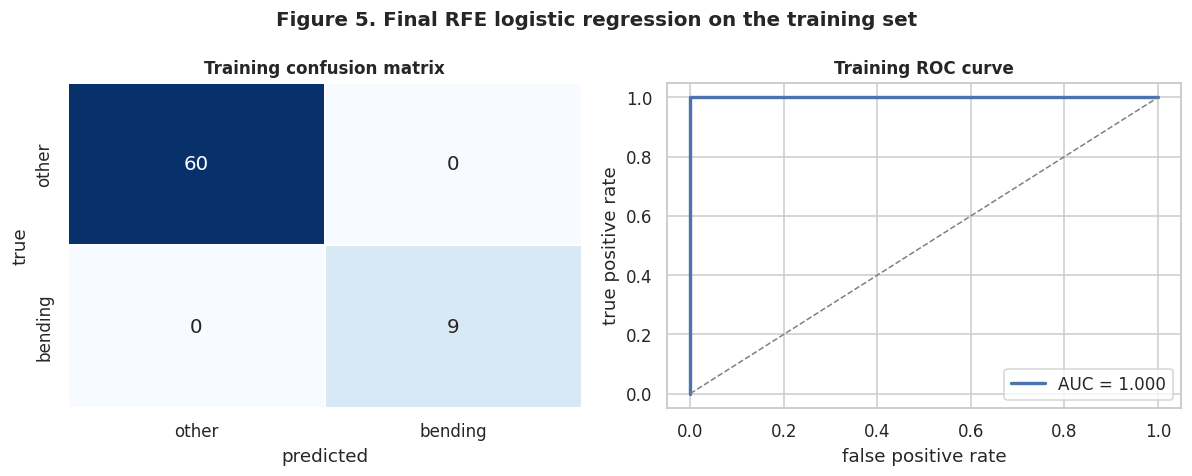

In [11]:
# Final model, refitted on the whole training set with (l*, p*).
Xtr_raw, Xte_raw = FEATURES[L_STAR].to_numpy()[train], FEATURES[L_STAR].to_numpy()[test]
ytr, yte = y_bin[train], y_bin[test]
scaler = StandardScaler().fit(Xtr_raw)
Xtr, Xte = scaler.transform(Xtr_raw), scaler.transform(Xte_raw)
selected = rfe_order(Xtr, ytr)[:P_STAR]
selected_names = list(FEATURES[L_STAR].columns[selected])
final = unpenalized_lr().fit(Xtr[:, selected], ytr)

train_score = final.predict_proba(Xtr[:, selected])[:, 1]
train_pred = final.predict(Xtr[:, selected])
print("Selected features:", ", ".join(selected_names))
print("Training accuracy", round(accuracy_score(ytr, train_pred), 4),
      "| training AUC", round(roc_auc_score(ytr, train_score), 4))


def plot_cm(ax, y_true, y_pred, labels, names, title):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    sns.heatmap(pd.DataFrame(cm, index=names, columns=names), annot=True, fmt="d", cmap="Blues",
                cbar=False, linewidths=1, linecolor="white", annot_kws={"size": 13}, ax=ax)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=11)


def plot_roc(ax, y_true, score, title, label=None):
    fpr, tpr, _ = roc_curve(y_true, score)
    ax.plot(fpr, tpr, lw=2.2, label=label or f"AUC = {roc_auc_score(y_true, score):.3f}")
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(title, fontsize=11); ax.legend(loc="lower right")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_cm(axes[0], ytr, train_pred, [0, 1], ["other", "bending"], "Training confusion matrix")
plot_roc(axes[1], ytr, train_score, "Training ROC curve")
fig.suptitle("Figure 5. Final RFE logistic regression on the training set", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

In [12]:
# Coefficients and Wald p values at the fitted coefficients. The covariance
# matrix is the inverse of the Fisher information X'WX, where W holds
# p times (one minus p) for every training instance.
design = np.column_stack([np.ones(len(Xtr)), Xtr[:, selected]])
beta = np.r_[final.intercept_, final.coef_.ravel()]
prob = 1 / (1 + np.exp(-design @ beta))
cov = np.linalg.pinv(design.T @ (design * (prob * (1 - prob))[:, None]))
se = np.sqrt(np.diag(cov))
coef_table = pd.DataFrame({"beta": beta, "std error": se, "z": beta / se,
                           "p value": 2 * stats.norm.sf(np.abs(beta / se))},
                          index=["intercept"] + selected_names)
print("Coefficients on standardized features, with Wald p values")
print(coef_table.round(4).to_string())

Coefficients on standardized features, with Wald p values
                 beta  std error       z  p value
intercept    -10.3049    25.1059 -0.4105   0.6815
min5_1         4.7756    61.0447  0.0782   0.9376
max5_1         4.5393    40.0724  0.1133   0.9098
3rd_quart1_1  -3.5133    42.9938 -0.0817   0.9349
1st_quart6_1  -2.2953    86.4394 -0.0266   0.9788
max4_1         2.3285    36.5322  0.0637   0.9492
1st_quart4_1  -1.9947    74.9108 -0.0266   0.9788
mean5_1        2.9552    88.7359  0.0333   0.9734
3rd_quart3_1  -1.4458    34.5518 -0.0418   0.9666
min1_1        -2.2598    31.8634 -0.0709   0.9435
max2_1        -1.9474    42.3926 -0.0459   0.9634
max1_1         1.5639    37.1976  0.0420   0.9665
std6_1        -1.3820    72.0008 -0.0192   0.9847


2(a)iv. The final model uses l = 1 and the 12 features chosen by RFE on the whole training set. On the training data it classifies all 69 instances correctly, so the confusion matrix is diagonal with 60 other and 9 bending instances, and the ROC curve passes through the top left corner with an AUC of 1.000.

The table above lists the coefficients on the standardized features with their Wald standard errors and p values. Every p value lies between 0.68 and 0.98, and the standard errors are many times larger than the coefficients themselves. I report these p values as computed, but they are not reliable inferential tests here. Under complete separation the maximum likelihood estimate does not exist, so the Wald statistics are evaluated at the coefficients where the optimizer stopped. Their large values therefore do not show that the features are uninformative, and indeed the model separates the training data perfectly. I discuss the separation in 2(a)vi.

#### v. Test Classifier

Test accuracy 1.0000 | test AUC 1.0000
Cross validated accuracy at (l, p) = (1, 12): 0.9857


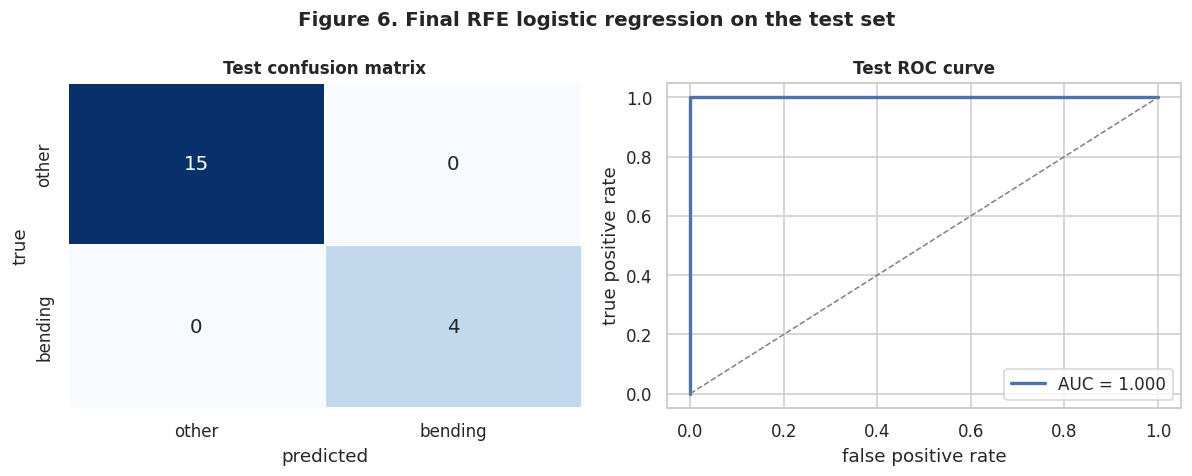

In [13]:
# The test series are split into the same l parts, and the scaler and the
# selected features learned on the training set are reused.
test_score = final.predict_proba(Xte[:, selected])[:, 1]
test_pred = final.predict(Xte[:, selected])
print(f"Test accuracy {accuracy_score(yte, test_pred):.4f} | test AUC {roc_auc_score(yte, test_score):.4f}")
print(f"Cross validated accuracy at (l, p) = ({L_STAR}, {P_STAR}): {cv_best:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
plot_cm(axes[0], yte, test_pred, [0, 1], ["other", "bending"], "Test confusion matrix")
plot_roc(axes[1], yte, test_score, "Test ROC curve")
fig.suptitle("Figure 6. Final RFE logistic regression on the test set", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

2(a)v. I split each test time series into the same l = 1 part, extracted the same features, and applied the scaler and the feature selection learned on the training set before predicting. All 19 test instances are classified correctly (15 other and 4 bending), so the test accuracy is 1.000, compared with the cross validated accuracy of 0.986. The two agree within sampling noise. A single test error would lower the test accuracy by 0.053, and the cross validated accuracy of the chosen pair is itself slightly optimistic, because it is the maximum over the 300 pairs I compared.

#### vi. Separation

Training accuracy, selected features: 1.0
Training accuracy, all 42 features  : 1.0
Iterations used by the unpenalized fit of 2(a)iv: 13 of a limit of 100

Coefficient norm as the L2 penalty is relaxed (tolerance 1e-12, and the default for comparison)
        C  training accuracy  coefficient norm  norm with default tolerance  iterations with default tolerance
      0.1              0.928             0.950                        0.950                                  9
      1.0              1.000             2.295                        2.294                                 11
     10.0              1.000             4.146                        4.141                                 14
    100.0              1.000             6.328                        6.374                                 13
   1000.0              1.000             8.726                        8.612                                 13
  10000.0              1.000            11.268                        9.568       

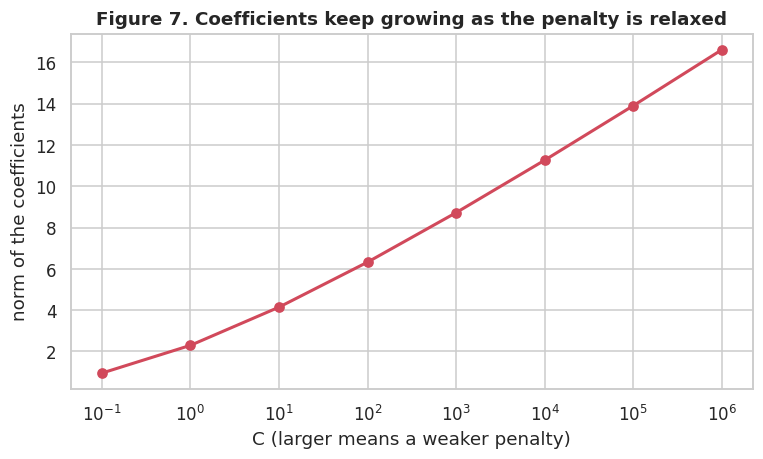

In [14]:
# Evidence for separation. (1) Training accuracy with the selected and with all
# features. (2) The coefficient norm as the penalty is relaxed. (3) What a
# standard maximum likelihood fit does.
print("Training accuracy, selected features:", accuracy_score(ytr, final.predict(Xtr[:, selected])))
print("Training accuracy, all 42 features  :",
      accuracy_score(ytr, unpenalized_lr().fit(Xtr, ytr).predict(Xtr)))
print("Iterations used by the unpenalized fit of 2(a)iv:", final.n_iter_[0], "of a limit of 100")

path = []
for C_value in [0.1, 1, 10, 100, 1000, 10000, 100000, 1000000]:
    tight = LogisticRegression(C=C_value, max_iter=100000, tol=1e-12).fit(Xtr[:, selected], ytr)
    default = LogisticRegression(C=C_value, max_iter=100000).fit(Xtr[:, selected], ytr)
    path.append({"C": C_value, "training accuracy": accuracy_score(ytr, tight.predict(Xtr[:, selected])),
                 "coefficient norm": np.linalg.norm(tight.coef_),
                 "norm with default tolerance": np.linalg.norm(default.coef_),
                 "iterations with default tolerance": default.n_iter_[0]})
path = pd.DataFrame(path)
print("\nCoefficient norm as the L2 penalty is relaxed (tolerance 1e-12, and the default for comparison)")
print(path.round(3).to_string(index=False))

# Depending on the statsmodels version, this maximum likelihood fit either
# returns with separation and convergence warnings or fails outright with a
# singular matrix. Both outcomes are evidence of the same instability, so the
# failure is caught and reported instead of stopping the notebook.
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    try:
        sm_fit = sm.Logit(ytr, sm.add_constant(Xtr[:, selected])).fit(disp=0, maxiter=200)
    except (np.linalg.LinAlgError, PerfectSeparationError) as exc:
        sm_fit = None
        print("\nstatsmodels maximum likelihood fit failed with", type(exc).__name__ + ",", exc)
if sm_fit is not None:
    print("\nstatsmodels maximum likelihood fit converged:", sm_fit.mle_retvals["converged"])
    print("largest absolute coefficient", round(np.abs(sm_fit.params).max(), 2),
          "| smallest p value", round(sm_fit.pvalues.min(), 4))
print("statsmodels version", sm.__version__, "| warnings raised:", sorted({w.category.__name__ for w in caught}))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.semilogx(path["C"], path["coefficient norm"], "o-", color="#D1495B", lw=2)
ax.set_xlabel("C (larger means a weaker penalty)")
ax.set_ylabel("norm of the coefficients")
ax.set_title("Figure 7. Coefficients keep growing as the penalty is relaxed")
plt.show()

2(a)vi. Yes. With the 12 selected features the two classes are perfectly separated on the training data, and they are also perfectly separated using all 42 features. When a separating hyperplane exists, the likelihood of the logistic regression keeps increasing as the coefficients grow along that direction, so the maximum likelihood estimate does not exist.

This instability shows up in three ways above. First, the statsmodels maximum likelihood fit breaks down. With statsmodels 0.15, which I used, it raises a PerfectSeparationWarning, does not converge, and gives p values of essentially 1. With other versions, such as 0.14.6, the same fit instead fails with a singular matrix error, which the code above catches and reports. Either outcome is a symptom of the same problem. Second, the coefficient norm keeps growing as the penalty is relaxed instead of settling at a finite value (Figure 7). It rises from 0.95 at C = 0.1 to 16.6 at $C = 10^6$, by roughly 2 to 2.7 for every tenfold increase in C once the training classes are separated. With the default tolerance the optimizer stops after 13 iterations for every C of 100 or more and hides this growth, so I computed the path with a much tighter tolerance. Third, the unpenalized fit of 2(a)iv also stops after only 13 iterations. Once every training instance is classified with high confidence the gradient of the likelihood is tiny, so the stopping rule is met long before the coefficients could diverge, and the reported coefficients reflect where the optimizer stopped rather than a true maximum. The fitted probabilities are then close to 0 or 1 for almost every instance, which makes the information matrix nearly singular and explains the huge standard errors and large Wald p values in 2(a)iv. Stopping early in this way is what footnote 5 suggests, and it keeps the estimates finite.

#### vii. Imbalance

case control sample: 9 cases and 9 controls
prevalence in training set 0.1304, in sample 0.50
intercept before -4.864, shift -1.897, after -6.762

 data  intercept  accuracy  false positives  false negatives  AUC
train unadjusted    0.9420                4                0  1.0
train   adjusted    0.9565                3                0  1.0
 test unadjusted    0.9474                1                0  1.0
 test   adjusted    0.9474                1                0  1.0


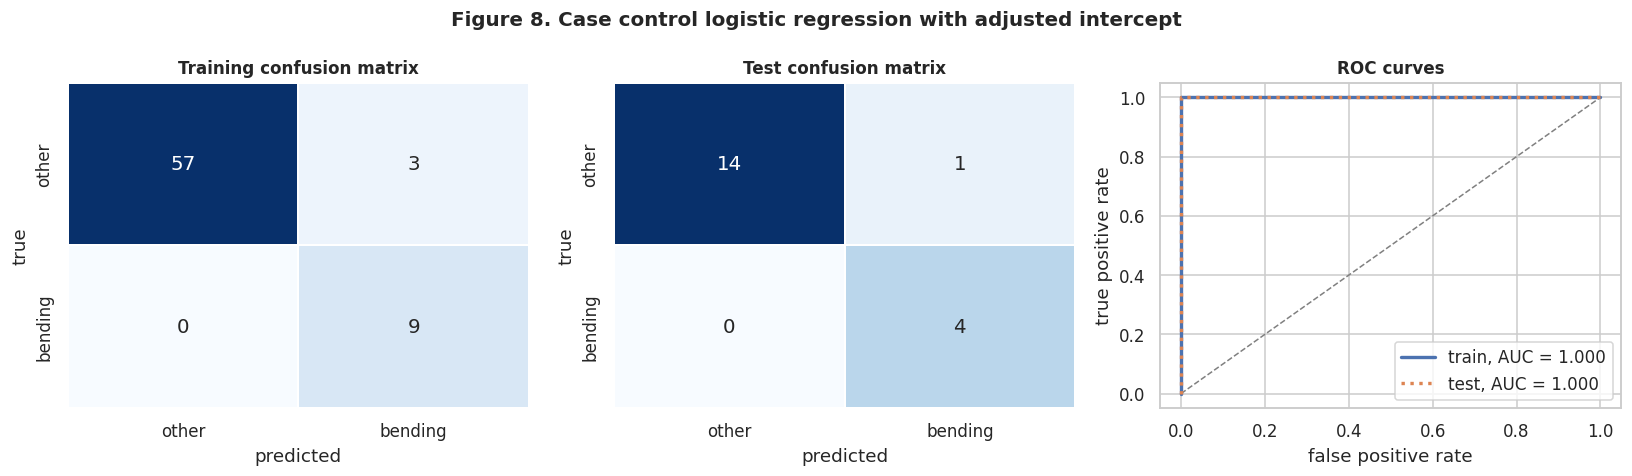

In [15]:
# Case control sampling. All bending instances (cases) and an equal number of
# randomly chosen other instances (controls). The slopes are fitted on this
# sample, and the intercept is corrected back to the training prevalence.
rng = np.random.default_rng(RANDOM_STATE)
cases = np.where(ytr == 1)[0]
controls = rng.choice(np.where(ytr == 0)[0], size=len(cases), replace=False)
cc_rows = np.r_[cases, controls]
cc_model = unpenalized_lr().fit(Xtr[cc_rows][:, selected], ytr[cc_rows])

pi_true, pi_sample = ytr.mean(), ytr[cc_rows].mean()
shift = np.log(pi_true / (1 - pi_true)) - np.log(pi_sample / (1 - pi_sample))
raw_intercept = cc_model.intercept_[0]
print(f"case control sample: {len(cases)} cases and {len(controls)} controls")
print(f"prevalence in training set {pi_true:.4f}, in sample {pi_sample:.2f}")
print(f"intercept before {raw_intercept:.3f}, shift {shift:.3f}, after {raw_intercept + shift:.3f}")


def cc_scores(X, adjusted):
    z = X[:, selected] @ cc_model.coef_.ravel() + raw_intercept + (shift if adjusted else 0.0)
    return 1 / (1 + np.exp(-z))


rows = []
for label, X, y in [("train", Xtr, ytr), ("test", Xte, yte)]:
    for adjusted in (False, True):
        s = cc_scores(X, adjusted)
        pred = (s >= 0.5).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        rows.append({"data": label, "intercept": "adjusted" if adjusted else "unadjusted",
                     "accuracy": accuracy_score(y, pred), "false positives": fp,
                     "false negatives": fn, "AUC": roc_auc_score(y, s)})
print()
print(pd.DataFrame(rows).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
plot_cm(axes[0], ytr, (cc_scores(Xtr, True) >= 0.5).astype(int), [0, 1], ["other", "bending"],
        "Training confusion matrix")
plot_cm(axes[1], yte, (cc_scores(Xte, True) >= 0.5).astype(int), [0, 1], ["other", "bending"],
        "Test confusion matrix")
plot_roc(axes[2], ytr, cc_scores(Xtr, True), "ROC curves", label=f"train, AUC = {roc_auc_score(ytr, cc_scores(Xtr, True)):.3f}")
fpr, tpr, _ = roc_curve(yte, cc_scores(Xte, True))
axes[2].plot(fpr, tpr, lw=2.2, ls=":", label=f"test, AUC = {roc_auc_score(yte, cc_scores(Xte, True)):.3f}")
axes[2].legend(loc="lower right")
fig.suptitle("Figure 8. Case control logistic regression with adjusted intercept",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

2(a)vii. Yes. The confusion matrices show 9 bending against 60 other instances in the training set and 4 against 15 in the test set, so bending makes up only 13% of the training data. The model in 2(a)iv happens to make no errors, but the imbalance is clear from the class totals.

I therefore built a case control sample with all 9 bending instances as cases and 9 randomly chosen other instances as controls, and fitted the same logistic regression on the 12 selected features. Sampling the two classes at different rates leaves the slope coefficients consistent but shifts the intercept, so I corrected it with

$$\hat\beta_0^{*} = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

where $\pi = 9/69 = 0.130$ is the proportion of bending in the training set and $\tilde\pi = 0.5$ is the proportion in the case control sample. The correction moves the intercept from $-4.86$ to $-6.76$.

With the adjusted intercept the model classifies 66 of the 69 training instances correctly, with 3 other instances predicted as bending, and 18 of the 19 test instances, with 1 false positive. Its AUC is 1.000 on both sets, because the correction shifts every score by the same amount and does not change their order. Without the correction the model makes 4 false positives on the training set instead of 3, and the same single false positive on the test set. With only 18 instances to learn from, the case control model is less accurate at the 0.5 threshold than the model fitted on all 69 training instances.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

Best cross validated accuracy 0.9857, reached by 9 pairs; simplest is l = 1, C = 0.5623
Nonzero coefficients 5 of 42:
3rd_quart1_1   -0.2927
min5_1          0.6313
max5_1          1.4534
median6_1      -0.0085
1st_quart6_1   -0.5925
Training accuracy 0.9855 | test accuracy 1.0000 | test AUC 1.0000


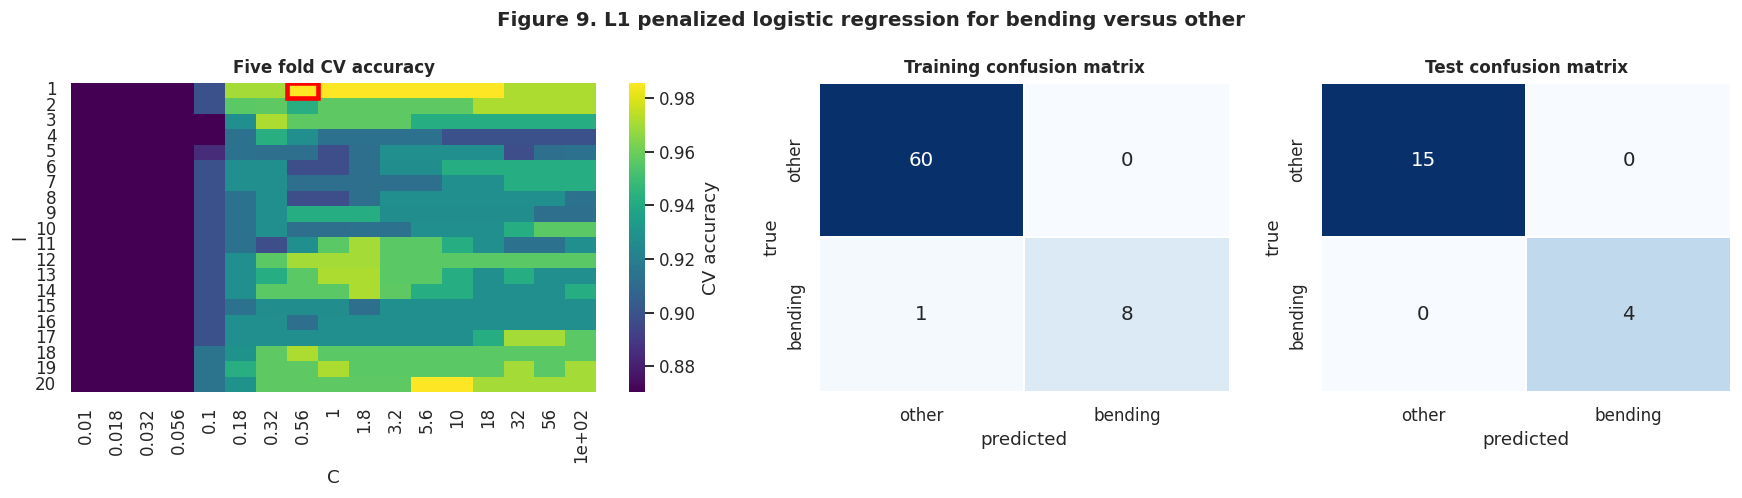

In [16]:
# L1 penalized logistic regression on standardized features. The scaler sits
# inside the pipeline, so it is refitted within every fold.
CS_L1 = np.logspace(-2, 2, 17)
cv_l1 = np.zeros((len(L_VALUES), len(CS_L1)))
for li, l in enumerate(L_VALUES):
    X = FEATURES[l].to_numpy()[train]
    for ci, C_value in enumerate(CS_L1):
        pipe = make_pipeline(StandardScaler(), LogisticRegression(
            C=C_value, solver="liblinear", max_iter=1000, random_state=0, **L1_ARGS))
        cv_l1[li, ci] = cross_val_score(pipe, X, ytr, cv=cv5).mean()

(li_l1, ci_l1), cv_l1_best, n_l1 = best_cell(cv_l1, key=lambda c: (c[0], c[1]))
L_L1, C_L1 = L_VALUES[li_l1], CS_L1[ci_l1]
print(f"Best cross validated accuracy {cv_l1_best:.4f}, reached by {n_l1} pairs; "
      f"simplest is l = {L_L1}, C = {C_L1:.4f}")

X1tr, X1te = FEATURES[L_L1].to_numpy()[train], FEATURES[L_L1].to_numpy()[test]
l1_model = make_pipeline(StandardScaler(), LogisticRegression(
    C=C_L1, solver="liblinear", max_iter=1000, random_state=0, **L1_ARGS)).fit(X1tr, ytr)
coef = l1_model[-1].coef_.ravel()
kept = np.flatnonzero(np.abs(coef) > 1e-10)
print(f"Nonzero coefficients {len(kept)} of {len(coef)}:")
print(pd.Series(coef[kept], index=FEATURES[L_L1].columns[kept]).round(4).to_string())
print(f"Training accuracy {accuracy_score(ytr, l1_model.predict(X1tr)):.4f} | "
      f"test accuracy {accuracy_score(yte, l1_model.predict(X1te)):.4f} | "
      f"test AUC {roc_auc_score(yte, l1_model.predict_proba(X1te)[:, 1]):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
sns.heatmap(pd.DataFrame(cv_l1, index=L_VALUES, columns=[f"{c:.2g}" for c in CS_L1]), cmap="viridis",
            cbar_kws={"label": "CV accuracy"}, ax=axes[0])
axes[0].add_patch(plt.Rectangle((ci_l1, li_l1), 1, 1, fill=False, edgecolor="red", lw=3))
axes[0].set_xlabel("C"); axes[0].set_ylabel("l"); axes[0].set_title("Five fold CV accuracy", fontsize=11)
plot_cm(axes[1], ytr, l1_model.predict(X1tr), [0, 1], ["other", "bending"], "Training confusion matrix")
plot_cm(axes[2], yte, l1_model.predict(X1te), [0, 1], ["other", "bending"], "Test confusion matrix")
fig.suptitle("Figure 9. L1 penalized logistic regression for bending versus other",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

2(b)i. I repeated the search with L1 penalized logistic regression on standardized features, using the liblinear solver recommended in footnote 9. I cross validated l from 1 to 20 together with the budget C over 17 values from 0.01 to 100 on a log scale, again with five fold stratified cross validation and with the scaler refitted inside each fold. The best cross validated accuracy is 0.986. It is reached by 9 pairs, and I chose the simplest one, with the smallest l and then the smallest C, which is l = 1 and C = 0.562.

The penalty keeps only 5 of the 42 features, namely 3rd_quart1_1, min5_1, max5_1, median6_1 and 1st_quart6_1, and sets all other coefficients exactly to zero. On the training set the model misclassifies one bending instance, and on the test set it classifies all 19 instances correctly.

#### ii. Comparison

2(b)ii. The two approaches perform equally well on this data. Both reach a cross validated accuracy of 0.986 and a test accuracy of 1.000. The L1 model is simpler, with 5 features instead of 12, and it is more stable, because the penalty keeps the coefficients finite even though the classes are separable, whereas the unpenalized model relies on stopping the optimizer early.

L1 penalized logistic regression is also easier to implement. It needs one convex fit for each value of C, and the variable selection is built into that fit. Selection by p values or by RFE needs a separate ranking step and many refits, and under separation the p values themselves are unreliable.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [17]:
# L1 penalized multinomial logistic regression (saga solver) for all seven
# activities. Within each fold the fits run along increasing C with warm
# starts, which gives the same models much faster. This cell takes a few minutes.
CS_M = np.array([0.1, 0.3, 1.0, 3.0, 10.0])
ym_tr, ym_te = y_multi[train], y_multi[test]


def multinomial_cv(l):
    X = FEATURES[l].to_numpy()[train]
    acc = np.zeros(len(CS_M))
    for tr, va in cv5.split(X, ym_tr):
        sc = StandardScaler().fit(X[tr])
        X_tr, X_va = sc.transform(X[tr]), sc.transform(X[va])
        model = LogisticRegression(solver="saga", max_iter=5000, tol=1e-3, random_state=0,
                                   warm_start=True, **L1_ARGS)
        for ci, C_value in enumerate(CS_M):
            model.set_params(C=C_value).fit(X_tr, ym_tr[tr])
            acc[ci] += accuracy_score(ym_tr[va], model.predict(X_va)) / 5
    return acc


cv_m = np.array([multinomial_cv(l) for l in L_VALUES])
(li_m, ci_m), cv_m_best, n_m = best_cell(cv_m, key=lambda c: (c[0], c[1]))
L_M, C_M = L_VALUES[li_m], CS_M[ci_m]
print(f"Best cross validated accuracy {cv_m_best:.4f}, reached by {n_m} pairs; simplest is l = {L_M}, C = {C_M}")

XMtr, XMte = FEATURES[L_M].to_numpy()[train], FEATURES[L_M].to_numpy()[test]
multi_model = make_pipeline(StandardScaler(), LogisticRegression(
    C=C_M, solver="saga", max_iter=5000, tol=1e-3, random_state=0, **L1_ARGS)).fit(XMtr, ym_tr)
CLASSES = list(multi_model.classes_)
multi_pred = multi_model.predict(XMte)
multi_proba = multi_model.predict_proba(XMte)
nonzero = int((np.abs(multi_model[-1].coef_) > 1e-10).sum())
print(f"Nonzero coefficients {nonzero} of {multi_model[-1].coef_.size}")
print(f"Test error {1 - accuracy_score(ym_te, multi_pred):.4f} "
      f"({int((multi_pred != ym_te).sum())} of {len(ym_te)} test instances misclassified)")
print(f"Macro average one versus rest AUC {roc_auc_score(ym_te, multi_proba, multi_class='ovr', labels=CLASSES):.4f}")

Best cross validated accuracy 0.8978, reached by 2 pairs; simplest is l = 1, C = 3.0
Nonzero coefficients 58 of 294
Test error 0.1053 (2 of 19 test instances misclassified)
Macro average one versus rest AUC 0.9940


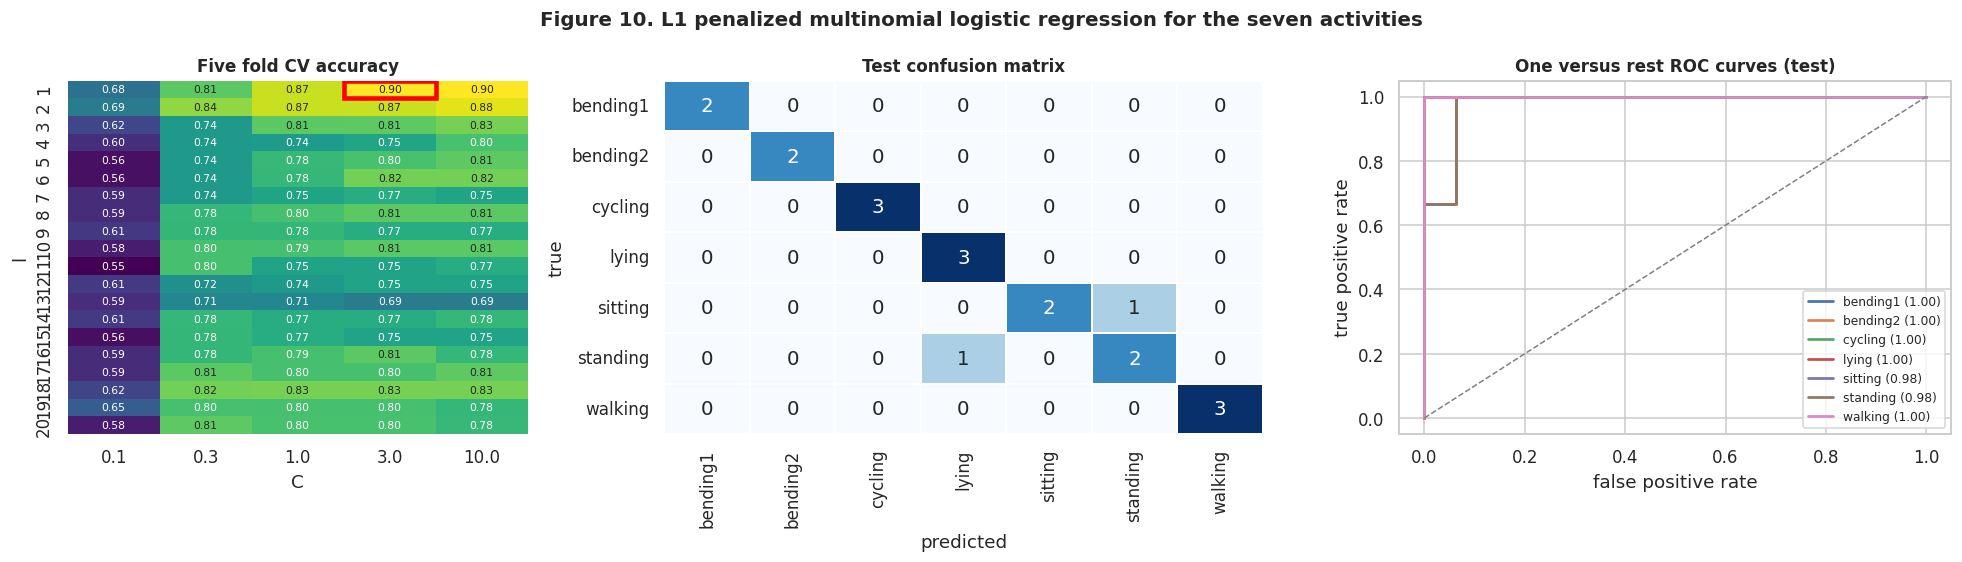

In [18]:
def plot_multiclass_roc(ax, y_true, proba, classes, title):
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve((y_true == c).astype(int), proba[:, k])
        ax.plot(fpr, tpr, lw=1.8, label=f"{c} ({roc_auc_score((y_true == c).astype(int), proba[:, k]):.2f})")
    ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
    ax.set_title(title, fontsize=11); ax.legend(fontsize=8, loc="lower right")


fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1.3, 1.2]})
sns.heatmap(pd.DataFrame(cv_m, index=L_VALUES, columns=CS_M), annot=True, fmt=".2f", cmap="viridis",
            cbar=False, annot_kws={"size": 7}, ax=axes[0])
axes[0].add_patch(plt.Rectangle((ci_m, li_m), 1, 1, fill=False, edgecolor="red", lw=3))
axes[0].set_xlabel("C"); axes[0].set_ylabel("l"); axes[0].set_title("Five fold CV accuracy", fontsize=11)
plot_cm(axes[1], ym_te, multi_pred, CLASSES, CLASSES, "Test confusion matrix")
plot_multiclass_roc(axes[2], ym_te, multi_proba, CLASSES, "One versus rest ROC curves (test)")
fig.suptitle("Figure 10. L1 penalized multinomial logistic regression for the seven activities",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

2(c)i. For the seven activities I used L1 penalized multinomial logistic regression on standardized features with the saga solver, and chose l and C by five fold stratified cross validation in the same way as in 2(b)i, with C in {0.1, 0.3, 1, 3, 10}. Because bending2 has only 4 training instances, one of the five folds has no bending2 instance in its validation part. The best cross validated accuracy is 0.898 at l = 1 and C = 3. The final model keeps 58 of its 294 coefficients. Its test error is 0.105, which means 2 of the 19 test instances are misclassified, one sitting instance predicted as standing and one standing instance predicted as lying.

For more than two classes the confusion matrix has one row for each true class and one column for each predicted class, so correct predictions lie on the diagonal and each off diagonal cell shows which pair of classes is confused. An ROC curve needs a binary problem, so I used the one versus rest approach. Each activity in turn is treated as the positive class and all others as negative, with the predicted probability of that activity as the score. This gives one ROC curve per class, and the macro average AUC over the seven curves is 0.994.

#### ii. Naive Bayes

Gaussian naive Bayes: best l = 1, CV accuracy 0.8538, test error 0.1053, macro AUC 0.9643
  CV accuracy for l = 1 to 20: [0.854 0.767 0.682 0.652 0.679 0.638 0.58  0.61  0.567 0.666 0.61  0.61
 0.609 0.549 0.579 0.535 0.552 0.507 0.549 0.535]


Multinomial naive Bayes: best l = 1, CV accuracy 0.8549, test error 0.1053, macro AUC 0.9851
  CV accuracy for l = 1 to 20: [0.855 0.767 0.782 0.738 0.782 0.767 0.813 0.767 0.798 0.738 0.753 0.753
 0.769 0.753 0.784 0.755 0.784 0.755 0.769 0.755]


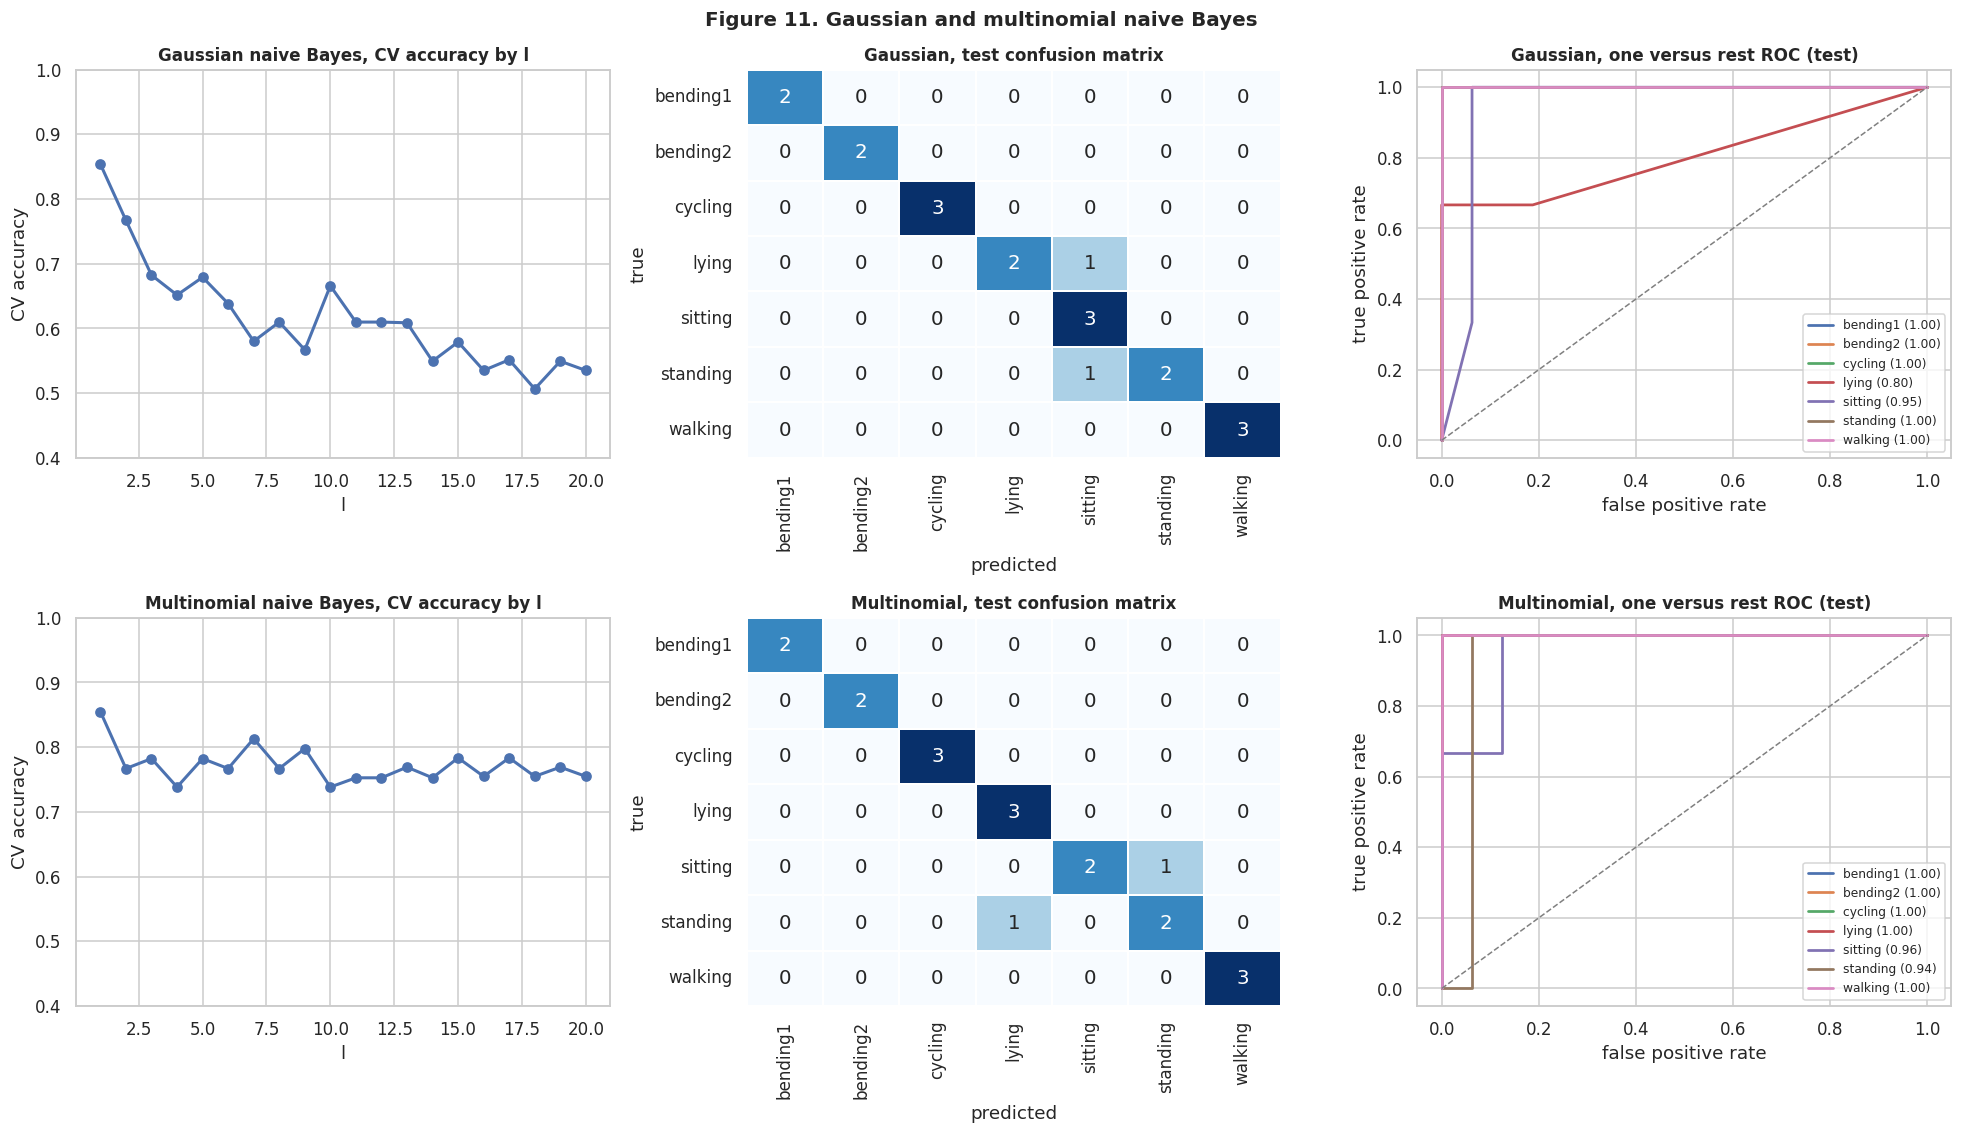

In [19]:
# Gaussian and multinomial naive Bayes, with l chosen by the same cross
# validation. All features are nonnegative, so the multinomial model can be
# fitted, although it assumes count data.
nb_results = {}
for name, make in [("Gaussian", GaussianNB), ("Multinomial", MultinomialNB)]:
    cvs = np.array([cross_val_score(make(), FEATURES[l].to_numpy()[train], ym_tr, cv=cv5).mean()
                    for l in L_VALUES])
    l_best = L_VALUES[int(np.argmax(cvs))]
    model = make().fit(FEATURES[l_best].to_numpy()[train], ym_tr)
    pred = model.predict(FEATURES[l_best].to_numpy()[test])
    proba = model.predict_proba(FEATURES[l_best].to_numpy()[test])
    nb_results[name] = {"cv": cvs, "l": l_best, "pred": pred, "proba": proba, "classes": list(model.classes_)}
    print(f"{name} naive Bayes: best l = {l_best}, CV accuracy {cvs.max():.4f}, "
          f"test error {1 - accuracy_score(ym_te, pred):.4f}, macro AUC "
          f"{roc_auc_score(ym_te, proba, multi_class='ovr', labels=model.classes_):.4f}")
    print("  CV accuracy for l = 1 to 20:", np.round(cvs, 3))

fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
for row, name in enumerate(["Gaussian", "Multinomial"]):
    r = nb_results[name]
    axes[row, 0].plot(L_VALUES, r["cv"], "o-", lw=2)
    axes[row, 0].set_xlabel("l"); axes[row, 0].set_ylabel("CV accuracy")
    axes[row, 0].set_title(f"{name} naive Bayes, CV accuracy by l", fontsize=11)
    axes[row, 0].set_ylim(0.4, 1.0)
    plot_cm(axes[row, 1], ym_te, r["pred"], r["classes"], r["classes"], f"{name}, test confusion matrix")
    plot_multiclass_roc(axes[row, 2], ym_te, r["proba"], r["classes"], f"{name}, one versus rest ROC (test)")
fig.suptitle("Figure 11. Gaussian and multinomial naive Bayes", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

2(c)ii. I chose l for each naive Bayes classifier by the same five fold cross validation. Both choose l = 1, with cross validated accuracies of 0.854 for Gaussian and 0.855 for multinomial naive Bayes, and both have a test error of 0.105, that is 2 of 19. Gaussian naive Bayes predicts one lying instance and one standing instance as sitting, while multinomial naive Bayes predicts one sitting instance as standing and one standing instance as lying. The macro average AUC is 0.964 for the Gaussian and 0.985 for the multinomial model.

The two models react differently to l. The cross validated accuracy of Gaussian naive Bayes falls from 0.854 at l = 1 to 0.535 at l = 20, while the multinomial model stays between 0.74 and 0.86. Splitting the series creates many strongly correlated features, and naive Bayes multiplies their likelihoods as if they were independent, so a likely reason for the drop is that the same evidence is counted many times. All features here are nonnegative, which is what allows multinomial naive Bayes to be fitted at all. Continuous summary statistics do not satisfy its usual assumption of count data, however, so the model is misspecified here, even though on this data it holds up better as l grows.

#### iii. Comparison

In [20]:
summary = pd.DataFrame([
    {"method": "L1 multinomial logistic regression", "l": L_M, "CV accuracy": cv_m_best,
     "test error": 1 - accuracy_score(ym_te, multi_pred),
     "macro AUC": roc_auc_score(ym_te, multi_proba, multi_class="ovr", labels=CLASSES)},
] + [
    {"method": f"{name} naive Bayes", "l": r["l"], "CV accuracy": r["cv"].max(),
     "test error": 1 - accuracy_score(ym_te, r["pred"]),
     "macro AUC": roc_auc_score(ym_te, r["proba"], multi_class="ovr", labels=r["classes"])}
    for name, r in nb_results.items()
])
print(summary.round(4).to_string(index=False))

                            method  l  CV accuracy  test error  macro AUC
L1 multinomial logistic regression  1       0.8978      0.1053     0.9940
              Gaussian naive Bayes  1       0.8538      0.1053     0.9643
           Multinomial naive Bayes  1       0.8549      0.1053     0.9851


2(c)iii. L1 penalized multinomial logistic regression is the better method for this problem. All three classifiers misclassify 2 of the 19 test instances, so the test set alone cannot separate them, but the multinomial logistic regression has the highest cross validated accuracy (0.898 against 0.854 and 0.855) and the highest macro average AUC (0.994 against 0.964 and 0.985). All the remaining test errors are among the static postures sitting, standing and lying, which are the hardest activities to tell apart with these features.

## 3. ISLR 4.8.3

4.8.3. The Bayes classifier assigns an observation x to the class k with the largest posterior probability $p_k(x) = \pi_k f_k(x) / \sum_{l=1}^{K} \pi_l f_l(x)$. The denominator is the same for every class, so this is equivalent to maximizing $\log(\pi_k f_k(x))$. With $X \mid Y = k \sim N(\mu_k, \sigma_k^2)$,

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right),$$

and dropping the constant $-\log\sqrt{2\pi}$, which is common to all classes, gives the discriminant function

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\, x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k .$$

The Bayes classifier assigns x to the class with the largest $\delta_k(x)$. In Section 4.4.1 all classes share one variance $\sigma^2$, so the term $-x^2/(2\sigma^2)$ is the same for every class and drops out of every comparison, which leaves a linear function of x. Here the variances differ, so the coefficient $-1/(2\sigma_k^2)$ of $x^2$ is different for each class and does not cancel. The boundary between classes k and l is where $\delta_k(x) = \delta_l(x)$, that is

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right) x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right) x + \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\right) = 0 ,$$

which is a quadratic equation in x whenever $\sigma_k \neq \sigma_l$. The Bayes classifier is therefore not linear but quadratic in x. This can also be seen directly. A linear rule splits the real line at a single threshold, but a quadratic boundary can have two roots, so the class with the larger variance can win in both tails, which no linear classifier can produce.

## 4. ISLR 4.8.7

4.8.7. By Bayes' theorem, with prior probabilities $\pi_{\text{Yes}} = 0.8$ and $\pi_{\text{No}} = 0.2$, class means $\mu_{\text{Yes}} = 10$ and $\mu_{\text{No}} = 0$, and common variance $\sigma^2 = 36$,

$$P(\text{Yes} \mid X = 4) = \frac{\pi_{\text{Yes}}\, f_{\text{Yes}}(4)}{\pi_{\text{Yes}}\, f_{\text{Yes}}(4) + \pi_{\text{No}}\, f_{\text{No}}(4)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma^2}\right).$$

The factor $1/\sqrt{2\pi\sigma^2}$ is the same for both classes and cancels, so

$$P(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752 .$$

The probability that the company issues a dividend this year is about 75.2%.

In [21]:
# Numerical check of 4.8.7.
f = lambda x, mu: stats.norm.pdf(x, loc=mu, scale=6)
print(f"P(Yes | X = 4) = {0.8 * f(4, 10) / (0.8 * f(4, 10) + 0.2 * f(4, 0)):.4f}")

P(Yes | X = 4) = 0.7519


## 5.1. Extra Practice ISLR 4.8.4

4.8.4(a). On average 10% of the observations. For a test point x the prediction uses the observations in an interval of length 0.1 around x, and because X is uniform on [0, 1] such an interval contains 10% of the data on average. If the interval is cut off at the edges of [0, 1] instead of being shifted inward, the average is slightly smaller, 9.75%.

4.8.4(b). On average $0.1 \times 0.1 = 1\%$ of the observations, because both conditions must hold and $X_1$ and $X_2$ are independent and uniform.

4.8.4(c). On average $0.1^{100} = 10^{-100}$ of the observations, which is essentially none.

4.8.4(d). The fraction of observations near a test point is $0.1^p$, which shrinks exponentially as p grows. With many features almost no training observations are close to any test point, so KNN has to rely on neighbours that are far away and no longer similar to the test point, which defeats the idea of a local average.

4.8.4(e). A hypercube that contains 10% of the observations on average has side length $0.1^{1/p}$, which is 0.1 for p = 1, 0.316 for p = 2 and 0.977 for p = 100. In 100 dimensions the cube must cover almost the whole range of every feature to contain 10% of the data, so the nearest neighbours are not local at all.

In [22]:
# Numerical check of 4.8.4 (a) with edges cut off, and of (e).
x = np.linspace(0, 1, 2_000_001)
print("(a) average fraction with the interval cut at the edges:",
      round(np.mean(np.minimum(x + 0.05, 1) - np.maximum(x - 0.05, 0)), 4))
for p in (1, 2, 100):
    print(f"(e) side length for p = {p}: {0.1 ** (1 / p):.3f}")

(a) average fraction with the interval cut at the edges: 0.0975
(e) side length for p = 1: 0.100
(e) side length for p = 2: 0.316
(e) side length for p = 100: 0.977


## 5.2. Extra Practice ISLR 4.8.9

4.8.9(a). Odds of 0.37 correspond to a probability of $0.37/(1+0.37) = 0.27$, so on average 27% of such people will default.

4.8.9(b). A probability of 0.16 corresponds to odds of $0.16/(1-0.16) = 0.16/0.84 = 0.19$.

## References

1. UCI Machine Learning Repository, Activity Recognition system based on Multisensor data fusion (AReM). https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. Palumbo, F., Gallicchio, C., Pucci, R., and Micheli, A. (2016). Human activity recognition using multisensor data fusion based on Reservoir Computing. Journal of Ambient Intelligence and Smart Environments, 8(2), pages 87 to 107.
3. James, G., Witten, D., Hastie, T., and Tibshirani, R. (2021). An Introduction to Statistical Learning, 2nd edition. Springer. Chapter 4 on classification and Section 6.2.2 on the lasso.
4. Hastie, T., Tibshirani, R., and Friedman, J. (2009). The Elements of Statistical Learning, 2nd edition. Springer. Section 7.10.2 on the wrong and the right way to do cross validation.
5. Guyon, I., Weston, J., Barnhill, S., and Vapnik, V. (2002). Gene selection for cancer classification using support vector machines. Machine Learning, 46, pages 389 to 422.
6. Albert, A., and Anderson, J. A. (1984). On the existence of maximum likelihood estimates in logistic regression models. Biometrika, 71(1), pages 1 to 10.
7. Fawcett, T. (2006). An introduction to ROC analysis. Pattern Recognition Letters, 27(8), pages 861 to 874.
8. scikit learn documentation for RFE, LogisticRegression, StratifiedKFold and naive Bayes. https://scikit-learn.org/stable/modules/feature_selection.html